# 06b — Phase 2 Final Master Comparison & Research Synthesis
**Author:** Kushal Sarkar (Phase 2 Lead Integration)  
**Team:** T033 — Project 26: Card Fraud Triage  
**Date:** 2026-11-16  

This notebook implements the final empirical synthesis for Phase 2, evaluating all 10 models (5 Phase 1 classical baselines + 5 Phase 2 deep learning and hybrid models) on the untouched chronological test split ($N=56,962$, 75 frauds).

### Core Research Questions Addressed:
1. **Does learning a non-linear compressed representation using an undercomplete Autoencoder improve fraud detection over classical density estimation (GMM) and classical projection (PCA)?**
2. **Does modeling the latent bottleneck distribution with a Gaussian Mixture Model (H1) resolve the curse of dimensionality, or does non-volume-preserving compression introduce distortion?**
3. **Does multi-objective hybrid scoring (H2 score fusion and H3 DAGMM-lite) yield statistically significant gains over standalone parents?**


In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.final_phase2 import ALL_MODELS, MODEL_DISPLAY, load_labels, load_scores
from src.metrics import pr_auc, precision_at_k
from src.evaluation import paired_bootstrap_diff

2026-11-17 18:02:59 | INFO     | src.data | Registered additional feature sets from src.features: ['raw', 'engineered', 'fe_norm_outliers', 'norm_outliers', 'fe_pca_whitened', 'pca_whitened', 'fe_robust_amount', 'robust_amount', 'fe_yeojohnson_amount', 'yeojohnson_amount', 'fe_time_risk', 'time_risk', 'fe_val_selected', 'val_selected']


In [2]:
y_val, y_test = load_labels()
s_val, s_test = load_scores("val"), load_scores("test")
for label, labels in [("Validation", y_val), ("Test", y_test)]:
    print(f"{label}: {len(labels):,} transactions, {int(labels.sum())} frauds ({labels.mean():.4%})")

Validation: 56,961 transactions, 57 frauds (0.1001%)
Test: 56,962 transactions, 75 frauds (0.1317%)


## 1. Master Headline Comparison Table
We display the full empirical comparison across all 10 models on the held-out test split, ordered by Test PR-AUC.


In [3]:
master_df = pd.read_csv(ROOT / "results/tables/final_comparison_phase2.csv")
master_df[["Model", "val_pr_auc", "test_pr_auc", "test_pr_auc_ci_lo",
           "test_pr_auc_ci_hi", "test_recall_fpr_0.5%", "test_prec_k_100"]]
# test_recall_fpr describes a point on the test ROC curve. See below for fixed policies.

Out[0]: 
                 Model  val_pr_auc  ...  test_recall_fpr_0.5%  test_prec_k_100
0       P1: PCA Recon.      0.7066  ...                0.7733             0.57
1     P2: Denoising AE      0.2935  ...                0.7733             0.53
2  P2: H2 Score Fusion      0.2935  ...                0.7733             0.53
3    P2: H3 DAGMM-lite      0.3913  ...                0.8000             0.48
4              P1: LOF      0.4069  ...                0.7200             0.47
5          P2: Deep AE      0.2272  ...                0.6800             0.40
6              P1: GMM      0.1038  ...                0.6667             0.31
7    P2: H1 Latent GMM      0.1159  ...                0.7467             0.30
8           P1: OC-SVM      0.0613  ...                0.6933             0.16
9      P1: Iso. Forest      0.0330  ...                0.3467             0.07

[10 rows x 7 columns]


,Model,val_pr_auc,test_pr_auc,test_pr_auc_ci_lo,test_pr_auc_ci_hi,test_recall_fpr_0.5%,test_prec_k_100
0,P1: PCA Recon.,0.7066,0.7425,0.6415,0.8368,0.7733,0.57
1,P2: Denoising AE,0.2935,0.4818,0.3707,0.6166,0.7733,0.53
2,P2: H2 Score Fusion,0.2935,0.4818,0.3707,0.6166,0.7733,0.53
3,P2: H3 DAGMM-lite,0.3913,0.4541,0.3524,0.5884,0.8000,0.48
4,P1: LOF,0.4069,0.4478,0.3447,0.5822,0.7200,0.47
5,P2: Deep AE,0.2272,0.3574,0.2618,0.4848,0.6800,0.40
6,P1: GMM,0.1038,0.2679,0.1843,0.3800,0.6667,0.31
7,P2: H1 Latent GMM,0.1159,0.1724,0.1329,0.2310,0.7467,0.30
8,P1: OC-SVM,0.0613,0.1322,0.1030,0.1784,0.6933,0.16
9,P1: Iso. Forest,0.0330,0.0577,0.0444,0.0787,0.3467,0.07


## 2. Statistical Significance Testing & Paired Differences
To determine whether observed metric differences between models reflect true representational superiority rather than finite-sample variability, we compute stratified paired bootstrap differences ($\Delta 	ext{PR-AUC}$ with 95% CIs) against baseline GMM and baseline PCA.


In [4]:
print("=== PAIRED BOOTSTRAP SIGNIFICANCE (vs GMM) ===")
for m in ["ae", "ae_dae", "hybrid_latentgmm", "hybrid_dagmmlite"]:
    res = paired_bootstrap_diff(y_test, s_test[m], s_test["gmm"], pr_auc, n=1000, seed=42)
    sig = "SIGNIFICANT" if res["significant"] else "NOT significant"
    print(f"{MODEL_DISPLAY[m]:20s} vs GMM: Δ = {res['diff_point']:+.4f} [95% CI: {res['ci_lo']:+.4f}, {res['ci_hi']:+.4f}] -> {sig}")

print("\n=== PAIRED BOOTSTRAP SIGNIFICANCE (vs PCA) ===")
for m in ["ae_dae", "hybrid_dagmmlite", "hybrid_latentgmm"]:
    res = paired_bootstrap_diff(y_test, s_test[m], s_test["pca"], pr_auc, n=1000, seed=42)
    sig = "SIGNIFICANT" if res["significant"] else "NOT significant"
    print(f"{MODEL_DISPLAY[m]:20s} vs PCA: Δ = {res['diff_point']:+.4f} [95% CI: {res['ci_lo']:+.4f}, {res['ci_hi']:+.4f}] -> {sig}")


=== PAIRED BOOTSTRAP SIGNIFICANCE (vs GMM) ===
P2: Deep AE          vs GMM: Δ = +0.0894 [95% CI: +0.0028, +0.1811] -> SIGNIFICANT
P2: Denoising AE     vs GMM: Δ = +0.2139 [95% CI: +0.1177, +0.3124] -> SIGNIFICANT
P2: H1 Latent GMM    vs GMM: Δ = -0.0955 [95% CI: -0.1923, -0.0185] -> SIGNIFICANT
P2: H3 DAGMM-lite    vs GMM: Δ = +0.1861 [95% CI: +0.0897, +0.2882] -> SIGNIFICANT

=== PAIRED BOOTSTRAP SIGNIFICANCE (vs PCA) ===
P2: Denoising AE     vs PCA: Δ = -0.2607 [95% CI: -0.3350, -0.1526] -> SIGNIFICANT
P2: H3 DAGMM-lite    vs PCA: Δ = -0.2884 [95% CI: -0.3669, -0.1779] -> SIGNIFICANT
P2: H1 Latent GMM    vs PCA: Δ = -0.5701 [95% CI: -0.6311, -0.4948] -> SIGNIFICANT


## Precision–recall curves and validation threshold policies

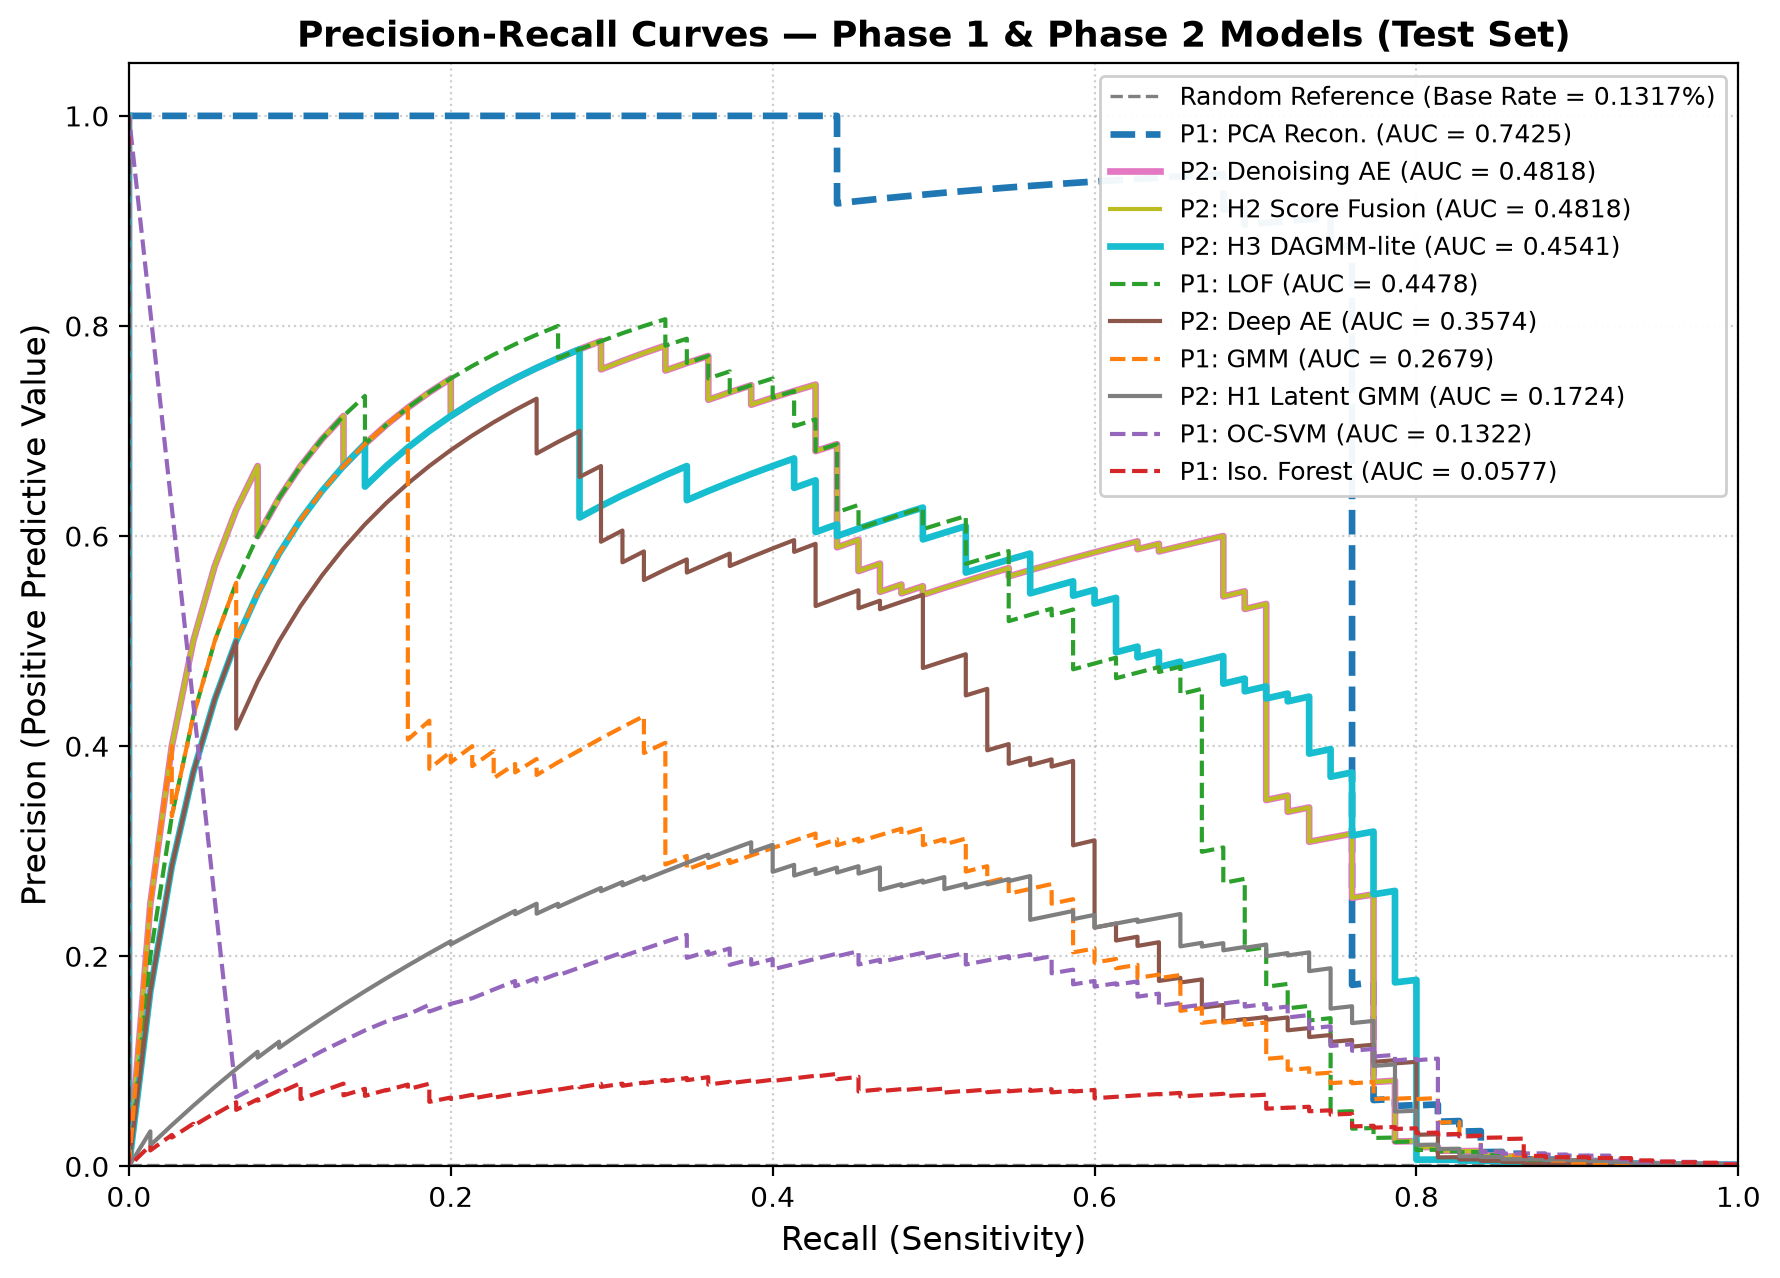

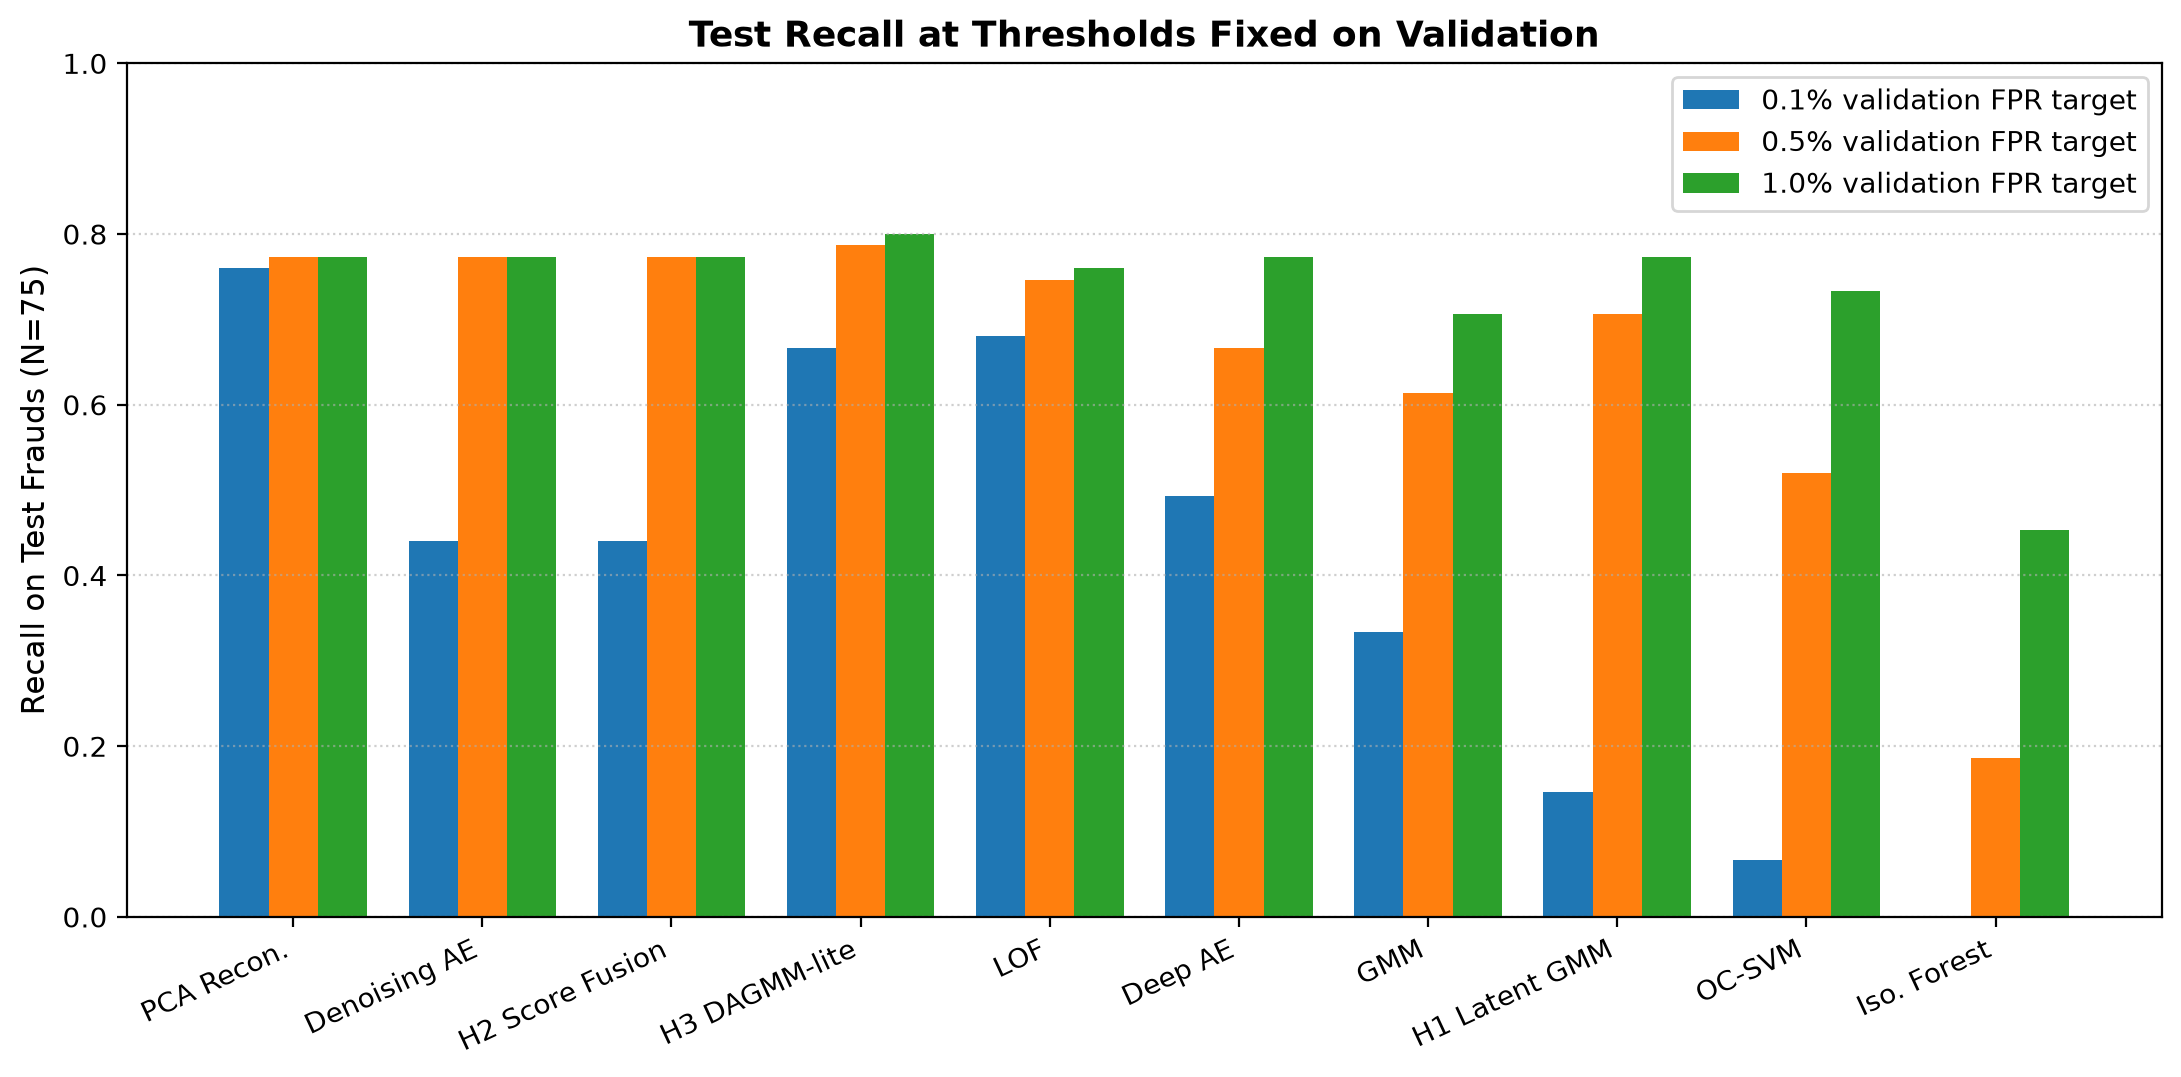

In [5]:
display(Image(filename=str(ROOT / "results/figures/final_phase2_pr_curves.png")))
display(Image(filename=str(ROOT / "results/figures/final_phase2_recall_at_fpr.png")))

## Test workload after fixing thresholds on validation
Each threshold is the relevant quantile of legitimate validation scores. Test FPR is the fraction of legitimate test transactions flagged. Review capacity uses the highest-scoring 100 transactions and can differ from the threshold workload.

In [6]:
policies = pd.read_csv(ROOT / "results/tables/final_thresholds_phase2.csv")
columns = ["model_key", "fpr_budget", "TP", "FP", "FN", "n_alerts", "test_fpr", "precision", "recall"]
display(policies[columns].round(4))
master_df[["Model", "test_prec_k_50", "test_prec_k_100", "test_prec_k_200"]]

Out[0]: 
                 Model  test_prec_k_50  test_prec_k_100  test_prec_k_200
0       P1: PCA Recon.            0.94             0.57            0.285
1     P2: Denoising AE            0.66             0.53            0.285
2  P2: H2 Score Fusion            0.66             0.53            0.285
3    P2: H3 DAGMM-lite            0.64             0.48            0.290
4              P1: LOF            0.66             0.47            0.260
5          P2: Deep AE            0.58             0.40            0.230
6              P1: GMM            0.38             0.31            0.220
7    P2: H1 Latent GMM            0.02             0.30            0.235
8           P1: OC-SVM            0.04             0.16            0.195
9      P1: Iso. Forest            0.02             0.07            0.070


,model_key,fpr_budget,TP,FP,FN,n_alerts,test_fpr,precision,recall
0,pca,0.001,57,84,18,141,0.0015,0.4043,0.7600
1,pca,0.005,58,332,17,390,0.0058,0.1487,0.7733
2,pca,0.010,58,692,17,750,0.0122,0.0773,0.7733
3,lof,0.001,51,128,24,179,0.0023,0.2849,0.6800
4,lof,0.005,56,977,19,1033,0.0172,0.0542,0.7467
5,lof,0.010,57,1511,18,1568,0.0266,0.0364,0.7600
6,gmm,0.001,25,53,50,78,0.0009,0.3205,0.3333
7,gmm,0.005,46,196,29,242,0.0034,0.1901,0.6133
8,gmm,0.010,53,396,22,449,0.0070,0.1180,0.7067
9,ocsvm,0.001,5,69,70,74,0.0012,0.0676,0.0667


,Model,test_prec_k_50,test_prec_k_100,test_prec_k_200
0,P1: PCA Recon.,0.94,0.57,0.285
1,P2: Denoising AE,0.66,0.53,0.285
2,P2: H2 Score Fusion,0.66,0.53,0.285
3,P2: H3 DAGMM-lite,0.64,0.48,0.290
4,P1: LOF,0.66,0.47,0.260
5,P2: Deep AE,0.58,0.40,0.230
6,P1: GMM,0.38,0.31,0.220
7,P2: H1 Latent GMM,0.02,0.30,0.235
8,P1: OC-SVM,0.04,0.16,0.195
9,P1: Iso. Forest,0.02,0.07,0.070


## What the scores show

- PCA achieves the highest test average precision (0.7425). DAE achieves 0.4818, followed by H3 at 0.4541 and standard AE at 0.3574.
- The GMM arrays in this checkout give 0.2679. The supplied Phase 1 report lists 0.4142. Paired intervals in this notebook use the checkout arrays.
- H2 selects zero GMM weight on validation. Its score preserves the DAE ranking.
- At the 0.5% validation FPR target, H3 catches 59 frauds and raises 197 false alarms. DAE catches 58 frauds and raises 186 false alarms. H3's realized test FPR is 0.346%. The test ROC point at a 0.5% FPR gives H3 60 of 75 frauds.
- H1 fitted on 12-dimensional latent codes has test AP 0.1724. Compression can discard information and can map different inputs to the same code, so the latent density does not identify their input-space density.

## Limits
The dataset spans two days and the test set has 75 frauds. The benchmark uses anonymized features. Several diagnostic sweeps report test metrics for multiple candidate models. Their recorded selection criteria use validation, and a new dataset would be needed for a fresh external evaluation.